# REAL IOP4, 8 July 2026: EarthCARE ATLID over SGP, the 20:30 UTC sonde, and two-way transmission T²

This notebook rebuilds, step by step, the IOP4 figure that puts an SGP C1 radiosonde and the
EarthCARE ATLID lidar on one pressure axis:

| panel | content |
|---|---|
| a | skew-T of the sonde launched 20:30:23 UTC (17 min before the overpass) |
| b | ATLID Mie co-polar attenuated backscatter (3-profile, 0.86 km along-track mean) |
| c | ATLID Rayleigh (molecular) attenuated backscatter (10 km × 0.3 km blocks) |
| d | two-way particle transmission **T²** retrieved from the Rayleigh channel |

Sections 7–8 spell out how T² is retrieved and what it can be used for.

**Authors:** Scott Collis (Argonne National Laboratory) with Claude (Anthropic).

**Data and credit**

* ARM Balloon-Borne Sounding System, `sgpsondewnpnC1.b1`, DOI [10.5439/1595321](https://doi.org/10.5439/1595321).
  Data from the U.S. DOE Atmospheric Radiation Measurement (ARM) user facility; thanks to the ARM SGP site
  operations team and the sonde instrument mentors.
* EarthCARE ATLID L1B `ATL_NOM_1B` (baseline BE), orbit/frame 11995D, DOI
  [10.57780/esa-98de183](https://doi.org/10.57780/esa-98de183). ESA/JAXA EarthCARE, accessed through ESA MAAP.

## 1. Setup

Requirements: `act-atmos`, `metpy`, `h5py`, `pyproj`, `pystac-client`, `requests`, `cmweather`,
`scipy`, `xarray`, `matplotlib`.

### Credentials

Nothing is hard-wired. Set environment variables before starting Jupyter, or replace the
`"enter key here"` placeholders below (do not commit real keys):

| variable | what | where to get it |
|---|---|---|
| `ARM_USERNAME`, `ARM_TOKEN` | ARM Live Data Webservice | https://adc.arm.gov/armlive/ |
| `MAAP_OFFLINE_TOKEN` | ESA MAAP 90-day offline token | https://portal.maap.eo.esa.int/ini/services/auth/token/90dToken.php |

Downloaded files go to `IOP4_DATA_DIR` (default `./data`, ignored by git). Files already present are
reused, so the 344 MB ATLID granule is only fetched once.

In [1]:
import os
from pathlib import Path

import act
import cmweather  # noqa: F401  (registers HomeyerRainbow)
import h5py
import matplotlib as mpl
import matplotlib.pyplot as plt
import metpy.calc as mpcalc
import numpy as np
import pandas as pd
import pystac_client
import requests
import xarray as xr
from matplotlib.colors import LogNorm
from matplotlib.ticker import FixedLocator, LogLocator, NullFormatter, NullLocator
from metpy.plots import SkewT
from metpy.units import units
from pyproj import Geod
from scipy.ndimage import uniform_filter1d
import warnings

warnings.filterwarnings('ignore', message='The input coordinates to pcolormesh')

ARM_USERNAME = os.environ.get('ARM_USERNAME', 'enter key here')
ARM_TOKEN = os.environ.get('ARM_TOKEN', 'enter key here')
MAAP_OFFLINE_TOKEN = os.environ.get('MAAP_OFFLINE_TOKEN', 'enter key here')

DATA = Path(os.environ.get('IOP4_DATA_DIR', 'data'))
FIGS = Path('figures')
DATA.mkdir(parents=True, exist_ok=True)
FIGS.mkdir(exist_ok=True)

mpl.rcParams.update({'font.size': 8, 'axes.titlesize': 8, 'axes.labelsize': 8,
                     'xtick.labelsize': 7, 'ytick.labelsize': 7, 'legend.fontsize': 7})
print('ACT', act.__version__, '| data dir:', DATA.name)

ACT 2.3.4 | data dir: nbtest_data


In [2]:
# Case definition
C1_LAT, C1_LON = 36.607, -97.488          # ARM SGP Central Facility
PASS_START, PASS_END = '2026-07-08T20:30:00Z', '2026-07-08T21:00:00Z'
WINDOW_KM = 300                           # along-track half-window read from the granule
geod = Geod(ellps='WGS84')

## 2. Fetch the radiosonde (ARM Live)

`act.discovery.download_arm_data` pulls every `sgpsondewnpnC1.b1` file for the day; the launch closest
before the overpass is picked in section 5.

In [3]:
sonde_dir = DATA / 'sgpsondewnpnC1.b1'
sonde_files = sorted(sonde_dir.glob('*.nc'))
if not sonde_files:
    act.discovery.download_arm_data(ARM_USERNAME, ARM_TOKEN, 'sgpsondewnpnC1.b1',
                                    '2026-07-08', '2026-07-08T23:59:59', output=str(sonde_dir))
    sonde_files = sorted(sonde_dir.glob('*.nc'))
print(len(sonde_files), 'sonde files:', [f.name.split('.')[-2] for f in sonde_files])

6 sonde files: ['080514', '113013', '143022', '173022', '203023', '232348']


## 3. Find and fetch the ATLID L1B granule (ESA MAAP)

Catalogue searches are anonymous. Downloading the HDF5 file needs a short-lived access token, obtained
by exchanging the 90-day offline token at the MAAP identity server. The client id/secret below are the
public values from ESA's MAAP examples (the same for every user), not a personal secret.

In [4]:
cat = pystac_client.Client.open('https://catalog.maap.eo.esa.int/catalogue/')
search = cat.search(collections=['EarthCAREL1Validated_MAAP'], datetime=f'{PASS_START}/{PASS_END}',
                    bbox=[C1_LON - 1, C1_LAT - 1, C1_LON + 1, C1_LAT + 1],
                    filter="product:type = 'ATL_NOM_1B'", filter_lang='cql2-text')
item = next(search.items())
print(item.id, '| DOI', item.properties.get('sci:doi'))


def maap_access_token(offline_token):
    r = requests.post(
        'https://iam.maap.eo.esa.int/realms/esa-maap/protocol/openid-connect/token',
        data={'grant_type': 'refresh_token', 'refresh_token': offline_token,
              'client_id': os.environ.get('MAAP_CLIENT_ID', 'offline-token'),
              'client_secret': os.environ.get('MAAP_CLIENT_SECRET', 'p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE'),
              'scope': 'offline_access openid'}, timeout=60)
    r.raise_for_status()   # 400 'Token is not active' means the 90-day token has expired
    return r.json()['access_token']


l1b_path = DATA / f'{item.id}.h5'
if not l1b_path.exists():
    hdr = {'Authorization': f'Bearer {maap_access_token(MAAP_OFFLINE_TOKEN)}'}
    with requests.get(item.assets['enclosure_h5'].href, headers=hdr, stream=True, timeout=600) as r:
        r.raise_for_status()
        with open(l1b_path, 'wb') as f:
            for chunk in r.iter_content(2**22):
                f.write(chunk)
print(l1b_path.name, f'{l1b_path.stat().st_size / 1e6:.0f} MB')

ECA_EXBE_ATL_NOM_1B_20260708T203929Z_20260708T234459Z_11995D | DOI 10.57780/esa-98de183
ECA_EXBE_ATL_NOM_1B_20260708T203929Z_20260708T234459Z_11995D.h5 344 MB


## 4. Read ATLID L1B and locate the closest approach to C1

ATLID is a 355 nm high-spectral-resolution lidar (HSRL) with three receiver channels:
**Mie co-polar** (particles), **Rayleigh** (molecules, separated from the particle return by a
Fabry–Perot etalon that passes the narrow particle line and reflects the Doppler-broadened molecular
spectrum) and **cross-polar**. L1B provides each as an attenuated backscatter in m⁻¹ sr⁻¹, sampled every
0.286 km along track and every 0.103 km in the vertical below 20.2 km.

Heights here are **MSL**: `sample_altitude` is relative to the WGS84 ellipsoid, so the geoid offset is
removed. (The SGP surface is ~0.32 km MSL; many ground-lidar products report heights AGL.)

In [5]:
def fill(a):
    a = np.asarray(a, dtype='f8')
    a[np.abs(a) > 1e30] = np.nan
    return a


with h5py.File(l1b_path) as f:
    sd = f['ScienceData']
    lat, lon = sd['ellipsoid_latitude'][:], sd['ellipsoid_longitude'][:]
    t = pd.to_datetime('2000-01-01') + pd.to_timedelta(sd['time'][:], unit='s')

_, _, d = geod.inv(np.full(lat.size, C1_LON), np.full(lat.size, C1_LAT), lon, lat)
ica = int(np.argmin(d))
_, _, s = geod.inv(np.full(lat.size, lon[ica]), np.full(lat.size, lat[ica]), lon, lat)
x_all = np.sign(lat - lat[ica]) * s / 1e3          # along-track km, north positive
sel = np.where(np.abs(x_all) <= WINDOW_KM)[0]
w = slice(sel[0], sel[-1] + 1)
CA = dict(t=t[ica], lat=lat[ica], lon=lon[ica], d=d[ica] / 1e3)
print(f"closest approach {CA['t']:%H:%M:%S.%f} UTC, {CA['d']:.2f} km from C1 "
      f"at {CA['lat']:.4f}N {abs(CA['lon']):.4f}W (profile {ica})")

with h5py.File(l1b_path) as f:
    sd = f['ScienceData']
    mie = fill(sd['mie_attenuated_backscatter'][w])
    ray = fill(sd['rayleigh_attenuated_backscatter'][w])
    xpol = fill(sd['crosspolar_attenuated_backscatter'][w])
    z = (fill(sd['sample_altitude'][w]) - sd['geoid_offset'][w][:, None]) / 1e3   # km MSL
    P = fill(sd['layer_pressure'][w])
    T = fill(sd['layer_temperature'][w])
    zsfc = sd['surface_elevation'][w] / 1e3
x = x_all[w]
X = np.broadcast_to(x[:, None], z.shape)
print('profiles in ±%d km:' % WINDOW_KM, len(x), '| levels:', z.shape[1],
      '| along-track step %.3f km' % np.abs(np.diff(x)).mean())

closest approach 20:47:45.016252 UTC, 19.81 km from C1 at 36.5718N 97.2709W (profile 12619)
profiles in ±300 km: 2100 | levels: 254 | along-track step 0.286 km


## 5. Process the sonde

* Pick the launch closest before the overpass.
* Average the 1 s data into 25 m layers (MetPy CAPE on raw ~4000-point RS41 profiles is unstable).
* Surface-based parcel, CAPE/CIN, LCL, EL and precipitable water with MetPy.
* Build `z2p`, the sonde height→pressure relation used to put ATLID on the skew-T pressure axis.

In [6]:
launch = pd.to_datetime([f.name.split('.')[2] + f.name.split('.')[3] for f in sonde_files], format='%Y%m%d%H%M%S')
lead = (CA['t'] - launch).total_seconds()
pick = sonde_files[int(np.argmin(np.where(lead >= 0, lead, np.inf)))]
ds = xr.open_dataset(pick)
print('sonde', pick.name, '| launched', str(ds.time.values[0])[:19],
      '| %.0f min before the pass' % ((CA['t'] - pd.Timestamp(ds.time.values[0])).total_seconds() / 60))

df = ds[['pres', 'tdry', 'dp', 'rh', 'wspd', 'deg', 'alt', 'lat', 'lon']].to_dataframe().reset_index()
df = df[(df.pres > 100) & df[['tdry', 'dp', 'pres']].notna().all(axis=1)]
df = df[df.pres.diff().fillna(-1) < 0]                       # ascent only
df['zb'] = (df.alt // 25) * 25
g = df.groupby('zb').mean(numeric_only=True).reset_index().merge(
    df.groupby('zb').time.min().reset_index(), on='zb')

p, Ts, Td = g.pres.values * units.hPa, g.tdry.values * units.degC, g.dp.values * units.degC
u, v = mpcalc.wind_components(g.wspd.values * units('m/s'), g.deg.values * units.deg)
parcel = mpcalc.parcel_profile(p, Ts[0], Td[0]).to('degC')
cape, cin = mpcalc.cape_cin(p, Ts, Td, parcel)
lcl_p, lcl_t = mpcalc.lcl(p[0], Ts[0], Td[0])
el_p, _ = mpcalc.el(p, Ts, Td, parcel)
pwv = mpcalc.precipitable_water(p, Td).to('mm')
z_sonde_sfc = g.alt.iloc[0] / 1e3


def z2p(zkm):
    return np.interp(zkm, g.alt.values / 1e3, g.pres.values, left=np.nan, right=np.nan)


print(f'SBCAPE {cape.m:.0f} J/kg, CIN {cin.m:.0f} J/kg, LCL {lcl_p.m:.0f} hPa, EL {el_p.m:.0f} hPa, '
      f'PWV {pwv.m:.1f} mm, surface {z_sonde_sfc:.3f} km MSL')

sonde sgpsondewnpnC1.b1.20260708.203023.nc | launched 2026-07-08T20:30:23 | 17 min before the pass
SBCAPE 3073 J/kg, CIN 0 J/kg, LCL 779 hPa, EL 183 hPa, PWV 45.5 mm, surface 0.320 km MSL


In [7]:
# Where did the balloon go relative to the ATLID track?
_, _, dca = geod.inv(g.lon.values, g.lat.values, np.full(len(g), CA['lon']), np.full(len(g), CA['lat']))
g['d_ca_km'] = dca / 1e3
sub = np.arange(0, len(x), 5)
_, _, dd = geod.inv(np.repeat(g.lon.values[:, None], sub.size, 1), np.repeat(g.lat.values[:, None], sub.size, 1),
                    np.tile(lon[w][sub], (len(g), 1)), np.tile(lat[w][sub], (len(g), 1)))
g['x_track'] = x[sub][np.argmin(dd, axis=1)]                # balloon projected onto the ATLID track
for zk in (2.5, 7.3, 10.5):
    i = np.argmin(np.abs(g.alt.values / 1e3 - zk))
    print(f'{zk:4.1f} km MSL: {g.time[i]:%H:%M:%S} UTC, RH {g.rh[i]:.0f}%, {g.d_ca_km[i]:.1f} km from CA, '
          f'along-track {g.x_track[i]:+.1f} km')

 2.5 km MSL: 20:36:21 UTC, RH 73%, 19.7 km from CA, along-track +2.9 km
 7.3 km MSL: 20:50:13 UTC, RH 48%, 14.6 km from CA, along-track -1.4 km
10.5 km MSL: 21:00:13 UTC, RH 13%, 13.3 km from CA, along-track -2.9 km


## 6. Mie co-polar channel

Native 0.286 km sampling is speckled, so a 3-profile (0.86 km) along-track running mean is applied;
the vertical stays native (0.103 km). No masking or filtering.

In [8]:
mie_s = uniform_filter1d(mie, 3, axis=0, mode='nearest')
pz = z2p(z)
lev = np.where(np.isfinite(pz).all(axis=0))[0]              # ATLID levels inside the sonde's range
w150 = np.abs(x) <= 150

prof = np.abs(x) <= 10
zc = np.nanmean(z[prof], axis=0)
mie10 = np.nanmean(mie[prof], axis=0)
band = (zc > 5.5) & (zc < 8.5)
z_peak = zc[band][np.nanargmax(mie10[band])]
LAYER = (z_peak - 0.3, z_peak + 0.3)
print(f'ATLID Mie peak within ±10 km: {z_peak:.2f} km MSL ({z_peak - z_sonde_sfc:.2f} km AGL); '
      f'layer band {LAYER[0]:.2f}-{LAYER[1]:.2f} km MSL')
i_pk = np.argmin(np.abs(g.alt.values / 1e3 - z_peak))
print(f'sonde at the peak: {g.time[i_pk]:%H:%M:%S} UTC, T {g.tdry[i_pk]:.1f} C, RH {g.rh[i_pk]:.0f}% -> dry aerosol, not cloud')

ATLID Mie peak within ±10 km: 7.27 km MSL (6.95 km AGL); layer band 6.97-7.57 km MSL
sonde at the peak: 20:50:04 UTC, T -14.6 C, RH 49% -> dry aerosol, not cloud


## 7. Retrieving two-way particle transmission T² from the Rayleigh channel

### 7.1 What the Rayleigh channel measures

For a down-looking lidar the Rayleigh-channel attenuated backscatter at height $z$ is

$$\beta'_R(z) \;=\; C\,\beta_m(z)\,T_m^2(z)\,T_p^2(z),\qquad
T_m^2 = e^{-2\tau_m(z)},\quad T_p^2 = e^{-2\tau_p(z)},$$

* $\beta_m$ molecular backscatter (follows air density),
* $T_m^2$ two-way transmission through the **molecules** above $z$ (large at 355 nm, ≈0.4 at the boundary layer),
* $T_p^2$ two-way transmission through the **particles** (aerosol, cloud) above $z$,
* $C$ a calibration constant.

ESA's L1B processing already removes the Mie↔Rayleigh spectral cross-talk of the etalon.

### 7.2 The clear-air model

From the L1B pressure and temperature (ECMWF on the lidar grid):

$$n = \frac{P}{k_B T},\qquad
\beta_m = n\,\sigma_\pi\left(\frac{355}{550}\right)^{-4.09},\ \ \sigma_\pi = 5.45\times10^{-32}\ \mathrm{m^2\,sr^{-1}},\qquad
\alpha_m = \frac{8\pi}{3}\beta_m,$$

$$\tau_m(z) = \int_z^{40\,\mathrm{km}} \alpha_m\,dz',\qquad \beta'_{mod}(z) = \beta_m\,e^{-2\tau_m}.$$

### 7.3 Averaging, calibration and the ratio

1. Block-average both $\beta'_R$ and $\beta'_{mod}$ over 35 profiles × 3 levels (10 km × 0.31 km), the
   scale at which the Rayleigh channel meets its 15 % accuracy requirement.
2. Calibrate in aerosol-free air (12–15 km), where $T_p^2 \approx 1$:
   $C = \langle\overline{\beta'_R}\rangle / \langle\overline{\beta'_{mod}}\rangle$.
3. Divide:

$$\boxed{\;T^2(z) \equiv T_p^2(z) = \frac{\overline{\beta'_R}}{C\,\overline{\beta'_{mod}}} = e^{-2\tau_p(z)}\;}$$

Dividing by the model removes both the density fall-off $\beta_m$ and the molecular attenuation $T_m^2$;
what is left is the fraction of light surviving the round trip through the particles above $z$.
T² runs from 1 (nothing lost) toward 0 (opaque cloud). It is extinction (scattering + absorption), not
absorption alone.

In [9]:
kB = 1.380649e-23
n = P / (kB * T)                                      # molecules m^-3
beta_m = n * 5.45e-32 * (355 / 550) ** -4.09          # m^-1 sr^-1
alpha_m = beta_m * 8 * np.pi / 3                      # m^-1
dz = np.abs(-np.diff(z, axis=1, append=z[:, -1:] - 0.1)) * 1e3
tau_m = np.nancumsum(np.nan_to_num(alpha_m) * dz, axis=1)   # index 0 is the top of the profile
beta_mod = beta_m * np.exp(-2 * tau_m)

NBX, NBZ = 35, 3
nx, nz = (z.shape[0] // NBX) * NBX, (z.shape[1] // NBZ) * NBZ


def blk(a):
    return np.nanmean(a[:nx, :nz].reshape(nx // NBX, NBX, nz // NBZ, NBZ), axis=(1, 3))


Rb, Bb, Xb, Zb = blk(ray), blk(beta_mod), blk(X), blk(z)
ref = (Zb > 12) & (Zb < 15)
C = np.nanmean(Rb[ref]) / np.nanmean(Bb[ref])
T2 = Rb / (C * Bb)
print(f'{Rb.shape[0]} x {Rb.shape[1]} blocks of {np.abs(np.diff(Xb[:, 0])).mean():.1f} km x '
      f'{np.median(np.abs(np.diff(Zb[len(Zb) // 2]))[np.nanmean(Zb, 0)[1:] < 20]):.2f} km (below 20 km);  C = {C:.2f};  '
      f'T² scatter at 12–15 km ±{np.nanstd(T2[ref]):.3f} (1σ per block)')

60 x 84 blocks of 10.0 km x 0.31 km (below 20 km);  C = 0.93;  T² scatter at 12–15 km ±0.055 (1σ per block)


 1.0 km MSL: T² = 0.40,  particle optical depth above = 0.46
 3.0 km MSL: T² = 0.55,  particle optical depth above = 0.30
 5.5 km MSL: T² = 0.69,  particle optical depth above = 0.18
 8.5 km MSL: T² = 0.98,  particle optical depth above = 0.01


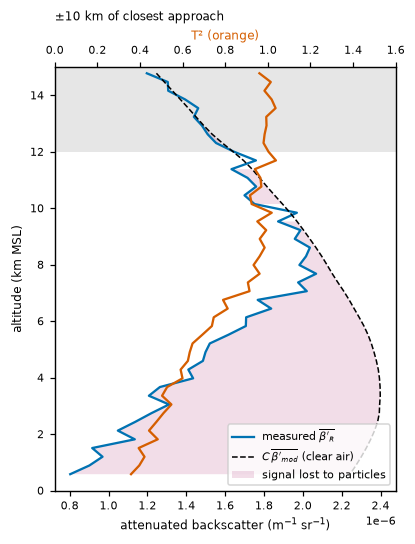

In [10]:
# Worked example: the ±10 km profile, the model and the ratio
near = np.abs(Xb[:, 0]) <= 10
zr = np.nanmean(Zb, axis=0)
R10, B10, T10 = (np.nanmean(a[near], axis=0) for a in (Rb, Bb, T2))
ok = (zr > 0.4) & (zr < 15)

fig, ax = plt.subplots(figsize=(4, 5))
ax.plot(R10[ok], zr[ok], color='#0072B2', label="measured $\\overline{\\beta'_R}$")
ax.plot(C * B10[ok], zr[ok], 'k--', lw=1, label="$C\\,\\overline{\\beta'_{mod}}$ (clear air)")
ax.fill_betweenx(zr[ok], R10[ok], C * B10[ok], where=R10[ok] < C * B10[ok], color='#CC79A7', alpha=0.25,
                 lw=0, label='signal lost to particles')
ax.axhspan(12, 15, color='0.9', lw=0, zorder=0)
ax.set(xlabel="attenuated backscatter (m$^{-1}$ sr$^{-1}$)", ylabel='altitude (km MSL)', ylim=(0, 15))
ax.legend(loc='lower right')
top = ax.twiny()
top.plot(T10[ok], zr[ok], color='#D55E00')
top.set_xlim(0, 1.6)
top.set_xlabel('T² (orange)', color='#D55E00')
ax.set_title('±10 km of closest approach', loc='left')
plt.show()
for zz in (1.0, 3.0, 5.5, 8.5):
    i = np.argmin(np.abs(zr - zz))
    print(f'{zz:4.1f} km MSL: T² = {T10[i]:.2f},  particle optical depth above = {-0.5 * np.log(T10[i]):.2f}')

### 7.4 Assumptions and caveats

* $\sigma_\pi$ and $8\pi/3$ are the simple Rayleigh forms (no King/Cabannes refinement). A constant error
  is absorbed by $C$; only its small height dependence through $\tau_m$ reaches T² (a few percent).
* If faint aerosol or ice sits at 12–15 km, $C$ absorbs it and T² is biased slightly high everywhere.
* Residual Mie→Rayleigh cross-talk would bias T² low inside the strongest layers.
* Beneath opaque cloud the Rayleigh signal is gone (T² → 0); those blocks carry no information below.

## 8. Using T²

T² is a nearly model-free column constraint. Four uses:

1. **Aerosol optical depth above any height:** $\tau_p(z) = -\tfrac{1}{2}\ln T^2(z)$.
2. **Extinction profile:** since $\tau_p(z)=\int_z^{top}\alpha_p\,dz'$ and $\ln T^2=-2\tau_p$, $\alpha_p(z) = +\tfrac{1}{2}\,\dfrac{d\ln T^2}{dz}$ (noisy; needs averaging).
3. **Attenuation-corrected particle backscatter.** The Mie channel sees the same path,
   $\beta'_M = C_M\,\beta_p\,T_m^2\,T_p^2$, so the transmission cancels in the channel ratio:
   $\beta_p = \beta_m\,C\,(\beta'_M + \beta'_\perp)/\beta'_R$ (assumes the L1B Mie and Rayleigh calibrations agree;
   the cross-polar term makes it total particle backscatter).
4. **Layer lidar ratio** without assumptions: $S = \Delta\tau_p \,/\, \int \beta_p\,dz$ across a layer.

It also tells ground lidars what they cannot see: a ground system looks up through the same aerosol in the
opposite direction, with one-way particle transmission to height $z$ of
$\sqrt{T^2(z_\mathrm{sfc})/T^2(z)}$.

In [11]:
xpb = blk(xpol)
Mb = blk(mie)
Bmb = blk(beta_m)
s50 = np.abs(Xb[:, 0]) <= 50
m_, x_, r_, b_ = (np.nanmean(a[s50], axis=0) for a in (Mb, xpb, Rb, Bmb))
T50 = r_ / (C * np.nanmean(Bb[s50], axis=0))
beta_p = (m_ + x_) * C * b_ / r_
lnT = uniform_filter1d(np.log(np.clip(T50, 1e-3, None)), 3)
alpha_p = 0.5 * np.gradient(lnT, zr * 1e3)           # m^-1, T² grows with height

rows = []
for lo_, hi_ in [(zsfc.mean() + 0.4, 3.0), (3.0, 6.5), (6.5, 8.0)]:
    k = (zr > lo_) & (zr < hi_)
    dtau = 0.5 * (np.log(T50[k][-1]) - np.log(T50[k][0]))     # zr decreases with index -> top is last
    ib = np.nansum(beta_p[k] * np.abs(np.gradient(zr * 1e3))[k])
    rows.append(dict(layer_km_MSL=f'{lo_:.1f}-{hi_:.1f}', AOD_layer=round(abs(dtau), 3),
                     mean_ext_per_km=round(np.nanmean(alpha_p[k]) * 1e3, 3),
                     mean_beta_p=f'{np.nanmean(beta_p[k]):.2e}', lidar_ratio_sr=round(abs(dtau) / ib, 1)))
print('±50 km of closest approach')
print(pd.DataFrame(rows).to_string(index=False))
print(f'AOD above the boundary layer ({zsfc.mean() + 0.4:.1f} km MSL): '
      f'{-0.5 * np.log(T50[np.argmin(np.abs(zr - (zsfc.mean() + 0.4)))]):.2f}')

±50 km of closest approach
layer_km_MSL  AOD_layer  mean_ext_per_km mean_beta_p  lidar_ratio_sr
     0.7-3.0      0.118            0.153    1.08e-06            50.7
     3.0-6.5      0.212            0.063    9.17e-07            62.5
     6.5-8.0      0.052            0.047    8.53e-07            39.9
AOD above the boundary layer (0.7 km MSL): 0.48


## 9. The IOP4 figure

Shared pressure axis: ATLID altitudes (MSL) are converted with the sonde's own height–pressure profile.
The dashed line is the balloon's path projected onto the ATLID track. Colour limits are fitted to the
signal between 0.5 and 12 km (Mie 5–99.5 %, Rayleigh 2–99.5 %), HomeyerRainbow throughout.

The dotted line is the ARM Doppler lidar mixed-layer depth at 20:30 UTC (≥ 2.38 km AGL, from
`sgpdlprofwstats4newsE13.c1`; taken from the REAL boundary-layer analysis, not recomputed here).

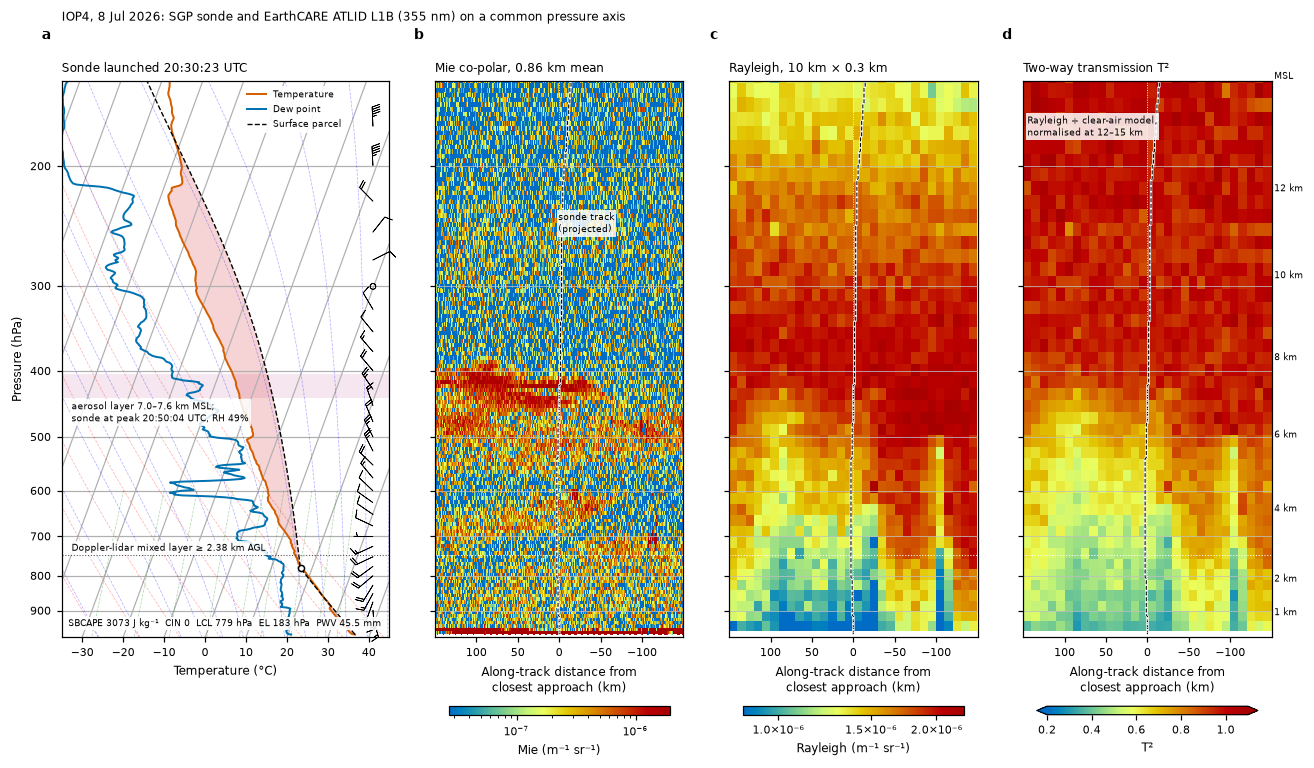

In [12]:
DL_MIXED_LAYER_AGL = 2.38
p_layer = z2p(np.array(LAYER))
p_bl = z2p(z_sonde_sfc + DL_MIXED_LAYER_AGL)
keep = [np.argmin(np.abs(g.pres.values - pp)) for pp in np.arange(925, 150, -25)]
ib = int(np.argmin(np.abs(g.pres.values - 250)))

vm = (z[w150] > 0.5) & (z[w150] < 12) & (mie_s[w150] > 0)
lo_m, hi_m = np.nanpercentile(mie_s[w150][vm], [5, 99.5])
bw = np.abs(Xb[:, 0]) <= 150
Pb = z2p(Zb)
levb = np.where(np.isfinite(Pb[bw]).all(axis=0))[0]
vr = (Zb > 0.5) & (Zb < 12) & (Rb > 0) & bw[:, None]
lo_r, hi_r = np.nanpercentile(Rb[vr], [2, 99.5])

fig = plt.figure(figsize=(12.5, 6.4))
gs = fig.add_gridspec(1, 4, width_ratios=[1.45, 1.1, 1.1, 1.1], wspace=0.17, left=0.05, right=0.93, bottom=0.11, top=0.9)
skew = SkewT(fig, rotation=20, subplot=gs[0], aspect='auto')
skew.ax.set_ylim(985, 150)
skew.ax.set_xlim(-35, 45)
skew.plot_dry_adiabats(lw=0.5, alpha=0.3)
skew.plot_moist_adiabats(lw=0.5, alpha=0.3)
skew.plot_mixing_lines(lw=0.5, alpha=0.3)
skew.shade_cape(p, Ts, parcel, alpha=0.2)
skew.plot(p, Ts, color='#D55E00', lw=1.3, label='Temperature')
skew.plot(p, Td, color='#0072B2', lw=1.3, label='Dew point')
skew.plot(p, parcel, color='k', lw=0.9, ls='--', label='Surface parcel')
skew.ax.plot(lcl_t.to('degC').m, lcl_p.m, 'o', ms=4, mfc='w', mec='k')
skew.plot_barbs(p[keep], u[keep].to('knots'), v[keep].to('knots'), length=5, linewidth=0.5, xloc=0.95)
skew.ax.legend(loc='upper right', bbox_to_anchor=(0.88, 1.0), fontsize=6, framealpha=0.9, edgecolor='none')
skew.ax.axhspan(p_layer[1], p_layer[0], color='#CC79A7', alpha=0.18, lw=0, zorder=0)
skew.ax.axhline(p_bl, color='0.3', lw=0.7, ls=':')
yt = skew.ax.get_yaxis_transform()
skew.ax.text(0.03, p_layer[0] + 4, f'aerosol layer {LAYER[0]:.1f}–{LAYER[1]:.1f} km MSL;\n'
             f'sonde at peak {g.time[i_pk]:%H:%M:%S} UTC, RH {g.rh[i_pk]:.0f}%', transform=yt, fontsize=6,
             va='top', bbox=dict(fc='w', ec='none', alpha=0.85, pad=1))
skew.ax.text(0.03, p_bl - 4, f'Doppler-lidar mixed layer ≥ {DL_MIXED_LAYER_AGL} km AGL', transform=yt,
             fontsize=6, va='bottom', bbox=dict(fc='w', ec='none', alpha=0.85, pad=1))
skew.ax.text(0.02, 0.02, f'SBCAPE {cape.m:.0f} J kg⁻¹  CIN {cin.m:.0f}  LCL {lcl_p.m:.0f} hPa  '
             f'EL {el_p.m:.0f} hPa  PWV {pwv.m:.1f} mm', transform=skew.ax.transAxes, fontsize=6,
             bbox=dict(fc='w', ec='none', alpha=0.9, pad=1))
skew.ax.set(xlabel='Temperature (°C)', ylabel='Pressure (hPa)')
skew.ax.set_title(f'Sonde launched {pd.Timestamp(ds.time.values[0]):%H:%M:%S} UTC', loc='left')

axM, axR, axT = (fig.add_subplot(gs[i]) for i in (1, 2, 3))
pmM = axM.pcolormesh(X[w150][:, lev], pz[w150][:, lev], np.where(mie_s[w150][:, lev] > 0, mie_s[w150][:, lev], lo_m / 10),
                     cmap='HomeyerRainbow', norm=LogNorm(lo_m, hi_m), shading='auto', rasterized=True)
pmR = axR.pcolormesh(Xb[bw][:, levb], Pb[bw][:, levb], np.where(Rb[bw][:, levb] > 0, Rb[bw][:, levb], lo_r / 10),
                     cmap='HomeyerRainbow', norm=LogNorm(lo_r, hi_r), shading='auto')
pmT = axT.pcolormesh(Xb[bw][:, levb], Pb[bw][:, levb], T2[bw][:, levb], cmap='HomeyerRainbow',
                     vmin=0.2, vmax=1.1, shading='auto')
axM.set_title('Mie co-polar, 0.86 km mean', loc='left')
axR.set_title('Rayleigh, 10 km × 0.3 km', loc='left')
axT.set_title('Two-way transmission T²', loc='left')
for ax in (axM, axR, axT):
    ax.plot(g.x_track, g.pres, color='w', lw=1.6)
    ax.plot(g.x_track, g.pres, color='k', lw=0.7, ls='--')
    ax.axvline(0, color='w', lw=0.6, ls=':')
    ax.axhline(p_bl, color='w', lw=0.7, ls=':')
    ax.set_xlim(150, -150)
    ax.set_xticks([100, 50, 0, -50, -100])
    ax.set_xlabel('Along-track distance from\nclosest approach (km)')
    ax.set_yscale('log')
    ax.set_ylim(985, 150)
    ax.yaxis.set_major_locator(FixedLocator(skew.ax.get_yticks()))
    ax.yaxis.set_minor_locator(NullLocator())
    ax.tick_params(labelleft=False)
    ax.grid(axis='y', color='0.75', lw=0.5)
axM.text(float(g.x_track[ib]) + 4, 250, 'sonde track\n(projected)', fontsize=6, ha='left',
         bbox=dict(fc='w', ec='none', alpha=0.85, pad=1))
axT.text(145, 168, 'Rayleigh ÷ clear-air model,\nnormalised at 12–15 km', fontsize=6, ha='left', va='top',
         bbox=dict(fc='w', ec='none', alpha=0.85, pad=1))
for zk in (1, 2, 4, 6, 8, 10, 12):
    axT.text(1.01, float(z2p(zk)), f'{zk} km', transform=axT.get_yaxis_transform(), fontsize=6, va='center')
axT.text(1.01, 150, 'MSL', transform=axT.get_yaxis_transform(), fontsize=6, va='bottom')
cbs = []
for ax, pm_, lab, ext in ((axM, pmM, 'Mie (m⁻¹ sr⁻¹)', 'neither'), (axR, pmR, 'Rayleigh (m⁻¹ sr⁻¹)', 'neither'),
                          (axT, pmT, 'T²', 'both')):
    pos = ax.get_position()
    cbs.append(fig.colorbar(pm_, cax=fig.add_axes([pos.x0 + 0.01, 0.0, pos.width - 0.02, 0.012]),
                            orientation='horizontal', extend=ext, label=lab))
cbs[0].ax.xaxis.set_major_locator(LogLocator(numticks=4))
cbs[0].ax.xaxis.set_minor_formatter(NullFormatter())
cbs[1].set_ticks([1e-6, 1.5e-6, 2e-6], labels=['1.0×10⁻⁶', '1.5×10⁻⁶', '2.0×10⁻⁶'])
cbs[1].ax.xaxis.set_minor_locator(NullLocator())
for ax, letter in zip((skew.ax, axM, axR, axT), 'abcd'):
    fig.text(ax.get_position().x0 - 0.008, 0.955, letter, fontsize=9, fontweight='bold', ha='right', va='bottom')
fig.suptitle('IOP4, 8 Jul 2026: SGP sonde and EarthCARE ATLID L1B (355 nm) on a common pressure axis',
             x=0.05, y=1.0, ha='left', fontsize=8)
fig.savefig(FIGS / 'iop4_skewt_atlid_mie_rayleigh_T2.png', dpi=300, bbox_inches='tight')
plt.show()

## 10. Summary

* EarthCARE passed 19.8 km east of SGP C1 at 20:47:45 UTC (descending orbit 11995D); the 20:30 UTC sonde
  drifted toward the track and stayed within a few km of closest approach along track.
* The ATLID Mie peak at ~7.3 km MSL (~6.9 km AGL) is a dry aerosol (smoke) layer: the sonde crossed it at
  RH < 50 %.
* The Rayleigh channel, divided by a clear-air model and calibrated at 12–15 km, gives the two-way particle
  transmission. Attenuation begins at the aerosol layer and deepens to T² ≈ 0.4 at the boundary layer near
  closest approach (AOD above the boundary layer ≈ 0.45 at 355 nm), with stronger attenuation north of
  closest approach than south.
* T² converts directly to AOD-above-height, extinction, attenuation-corrected backscatter and a layer lidar
  ratio, and is the natural bridge to ground lidars, which see the same aerosol from below.